# Сравнение независимых экспериментов LFPG, EGLL и EDDF

Каждая модель обучена отдельно для своего аэропорта. Зафиксированы исходные сезонные дни 1.1: девять train, три validation и три test. Горизонт 27–33 секунды, поправка к физическому baseline, равный вклад заходов. Перенос обученной модели между аэропортами здесь не исследуется

,model,macro_mae_ft,macro_rmse_ft,run_id,airport
0,Constant vertical rate,49.348959,67.995818,af81171321ba41da902589bff85a3858,LFPG
1,Ridge,20.033286,25.796078,58f9e5e9015e4478b4c9631b4aa613d0,LFPG
2,Polynomial Ridge,17.163963,22.244615,54224c6909c1451aa7c24c45feaa2dc5,LFPG
3,PyTorch MLP,18.862559,24.466738,e1e47564e32845768281b8f447e7e21b,LFPG
4,Constant vertical rate,55.953272,81.923198,77511f5022e34b5caf1c988466047793,EGLL
5,Ridge,16.337442,24.521356,019df70260ad45ec9299b2efc60829cc,EGLL
6,Polynomial Ridge,15.448957,24.743112,a1836409248444b0ae6250bd2a1aa52c,EGLL
7,PyTorch MLP,14.516123,20.314007,7432f453bb1e46e0924dc4ae5bfb212a,EGLL
8,Constant vertical rate,72.603506,117.367842,ab3f157c9a354866bb3673c2dd4f4138,EDDF
9,Ridge,22.225478,32.310559,586f82fc484d45c69e23761575b0b58b,EDDF


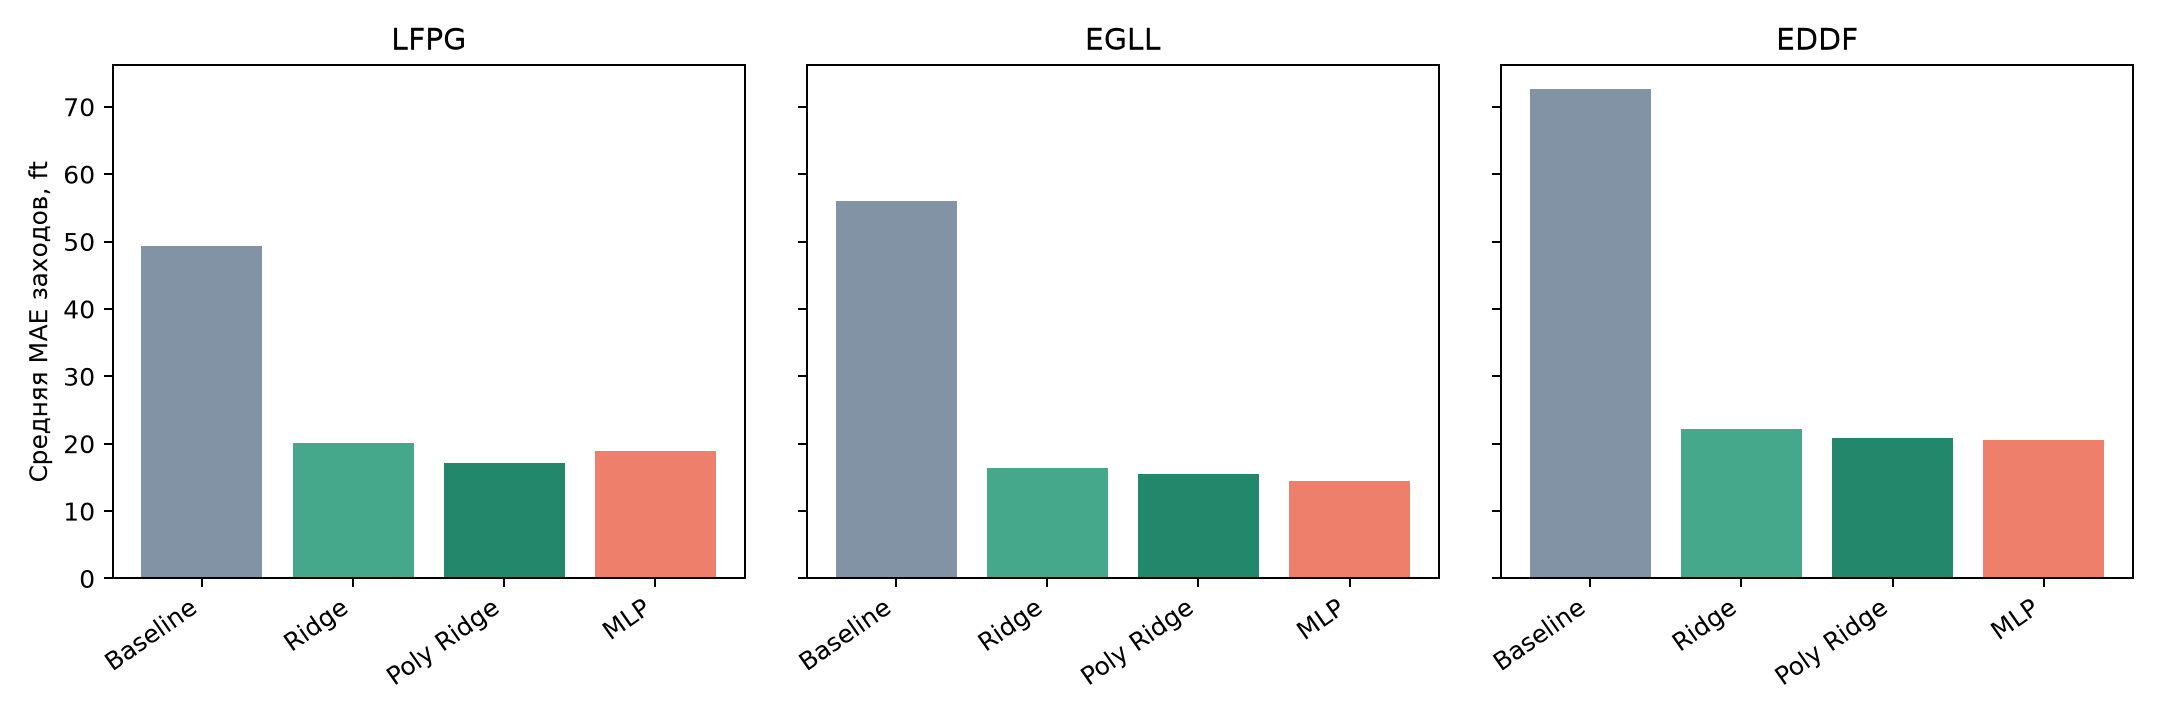

In [1]:
# Загружаем сохраненные результаты без повторного обучения
from pathlib import Path
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
display(pd.read_csv(root / "reports/three_airports_metrics.csv"))
display(Image(filename=str(root / "reports/three_airports_comparison.png")))

## EGLL: выборка, загрузка и выбор модели

Данные проходят те же проверки причинности и согласованности. Дополнительное поле airport_elevation_ft сохранено в PostgreSQL как метаданные. Повторная загрузка не добавляет строк. Все модели этого аэропорта оценены на одинаковом test. Классические MAE сверены с 1.1

,season,split,rows,events
0,autumn,test,13472,367
1,autumn,train,39770,1146
2,autumn,validation,12151,362
3,spring,test,7014,385
4,spring,train,19537,1136
5,spring,validation,6457,388
6,summer,test,15224,384
7,summer,train,41384,1156
8,summer,validation,11499,277


{'read': 166508, 'inserted': 0, 'already_present': 166508, 'database_rows': 166508, 'extracted': 166508, 'roundtrip_exact': True}


,model,parameter,validation_macro_mae_ft
0,Ridge,1,16.183624
1,Ridge,10,16.168880
2,Ridge,100,16.244204
3,Polynomial Ridge,1,15.751428
4,Polynomial Ridge,10,15.729394
5,Polynomial Ridge,100,15.972120
6,PyTorch MLP,16,15.023992
7,PyTorch MLP,32,14.886854


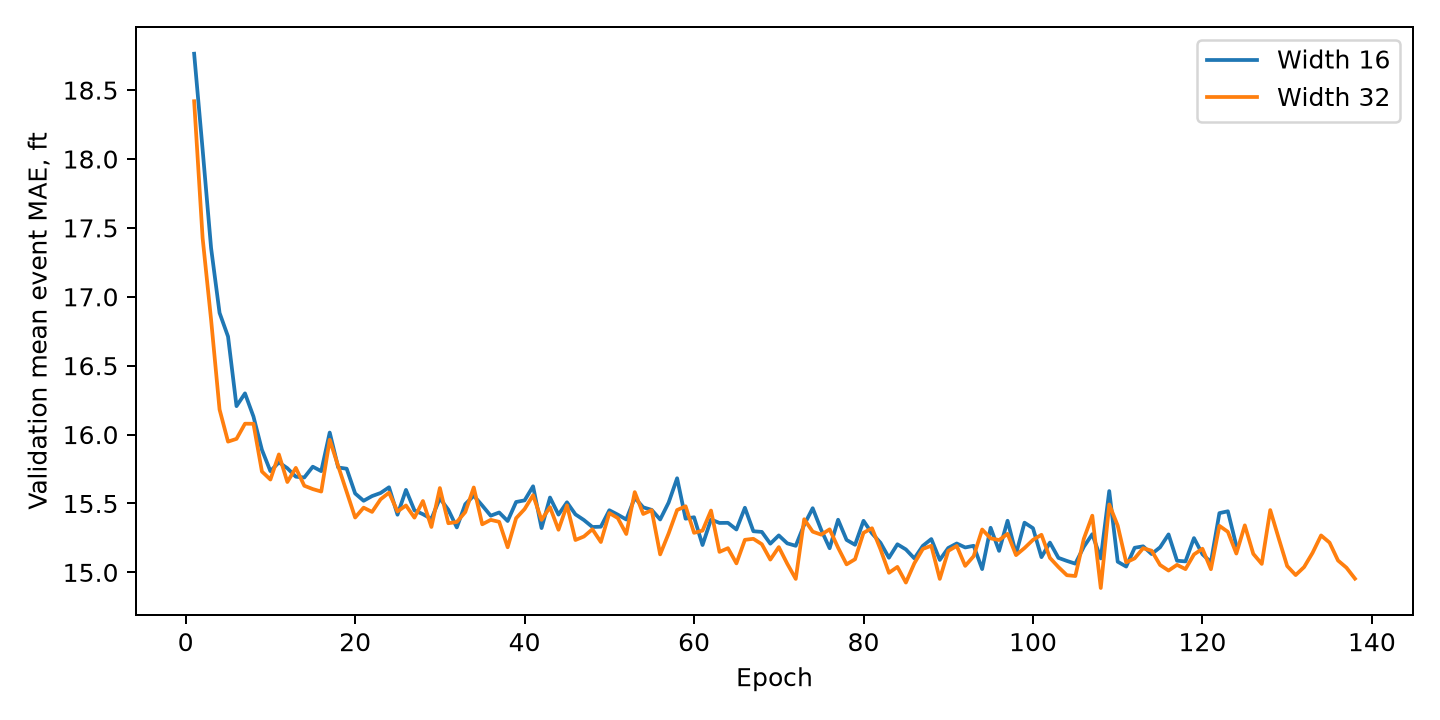

In [2]:
# Показываем инвентаризацию, проверку импорта и выбор по validation
display(pd.read_csv(root / "reports/EGLL/split_inventory.csv"))
print(json.loads((root / "reports/EGLL/ingestion.json").read_text()))
display(pd.read_csv(root / "reports/EGLL/validation_search.csv"))
display(Image(filename=str(root / "reports/EGLL/mlp_validation.png")))

## EDDF: выборка, загрузка и выбор модели

Данные проходят те же проверки причинности и согласованности. Дополнительное поле airport_elevation_ft сохранено в PostgreSQL как метаданные. Повторная загрузка не добавляет строк. Все модели этого аэропорта оценены на одинаковом test. Классические MAE сверены с 1.1

,season,split,rows,events
0,autumn,test,5919,172
1,autumn,train,21967,566
2,autumn,validation,6807,189
3,spring,test,6595,206
4,spring,train,9246,458
5,spring,validation,3759,177
6,summer,test,6823,162
7,summer,train,29215,533
8,summer,validation,6383,171


{'read': 96714, 'inserted': 0, 'already_present': 96714, 'database_rows': 96714, 'extracted': 96714, 'roundtrip_exact': True}


,model,parameter,validation_macro_mae_ft
0,Ridge,1,22.398563
1,Ridge,10,22.367554
2,Ridge,100,22.354038
3,Polynomial Ridge,1,21.080186
4,Polynomial Ridge,10,21.125482
5,Polynomial Ridge,100,21.635613
6,PyTorch MLP,16,20.682799
7,PyTorch MLP,32,20.528188


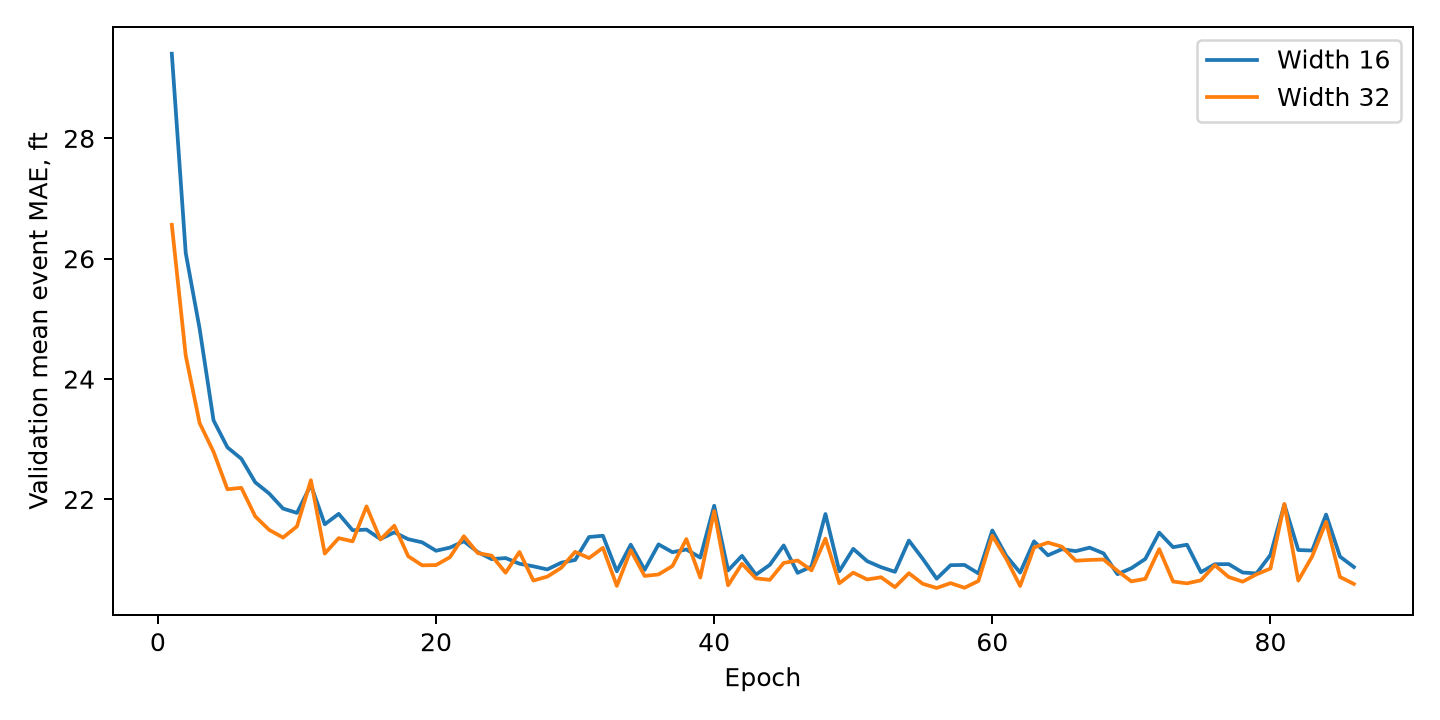

In [3]:
# Показываем инвентаризацию, проверку импорта и выбор по validation
display(pd.read_csv(root / "reports/EDDF/split_inventory.csv"))
print(json.loads((root / "reports/EDDF/ingestion.json").read_text()))
display(pd.read_csv(root / "reports/EDDF/validation_search.csv"))
display(Image(filename=str(root / "reports/EDDF/mlp_validation.png")))

## Ограничения сравнения

Размер и состав выборок различаются; абсолютная MAE не определяет сложность аэропорта. На сезон приходится один тестовый день, борта могут повторяться между split, фактический горизонт известен ретроспективно. Для MLP использован один seed. Сезонный анализ ошибок и интервалы LFPG не переносятся автоматически на EGLL/EDDF. Новые параметры по test не подбирались. Эксплуатационная применимость не установлена